In [1]:
import numpy as np
import scipy as sp 
import matplotlib.pyplot as plt


# Simulating Ising Model
$$\sum_i \sigma^z_i \sigma^z_{i+1}+h\sigma^z_i$$

In [ ]:
sigmaz=np.array([[1,0],[0,-1]],dtype=float)
print(sigmaz)
eigenvals,eigenvec=sp.linalg.eigh(sigmaz)
print(eigenvals)
N=10
J=-20
id=np.eye(2)
def single_site_op(op,site):
    result=1
    for i in range(N):
        if i==site:
            result=np.kron(result,op)
        else:
            result=np.kron(result,id)
    return result
H=0
for i in range(N):
    if i+1==N:
        break

    else:
        H+=J*single_site_op(sigmaz,i)@single_site_op(sigmaz,i+1)
        
    print(H)


[[ 1.  0.]
 [ 0. -1.]]
[-1.  1.]
[[-20.   0.   0. ...   0.   0.   0.]
 [  0. -20.   0. ...   0.   0.   0.]
 [  0.   0. -20. ...   0.   0.   0.]
 ...
 [  0.   0.   0. ... -20.   0.   0.]
 [  0.   0.   0. ...   0. -20.   0.]
 [  0.   0.   0. ...   0.   0. -20.]]
[[-40.   0.   0. ...   0.   0.   0.]
 [  0. -40.   0. ...   0.   0.   0.]
 [  0.   0. -40. ...   0.   0.   0.]
 ...
 [  0.   0.   0. ... -40.   0.   0.]
 [  0.   0.   0. ...   0. -40.   0.]
 [  0.   0.   0. ...   0.   0. -40.]]
[[-60.   0.   0. ...   0.   0.   0.]
 [  0. -60.   0. ...   0.   0.   0.]
 [  0.   0. -60. ...   0.   0.   0.]
 ...
 [  0.   0.   0. ... -60.   0.   0.]
 [  0.   0.   0. ...   0. -60.   0.]
 [  0.   0.   0. ...   0.   0. -60.]]
[[-80.   0.   0. ...   0.   0.   0.]
 [  0. -80.   0. ...   0.   0.   0.]
 [  0.   0. -80. ...   0.   0.   0.]
 ...
 [  0.   0.   0. ... -80.   0.   0.]
 [  0.   0.   0. ...   0. -80.   0.]
 [  0.   0.   0. ...   0.   0. -80.]]
[[-100.    0.    0. ...    0.    0.    0.]
 [   0. -100

In [10]:
evalue,evector=sp.linalg.eigh(H)

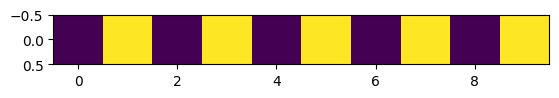

In [8]:
def state_to_bin(vec):
    a=np.argmax(vec**2)
    return list(map(int, format(format(a, f"0{N}b"))))
plt.imshow([state_to_bin(evector[:,0])])

### Introduce Temperature Boltzmann weight
$$ P_i=\text{e}^{-\frac{E_i}{T}}$$ $$\lvert \psi\rangle=\sum_i P_i \lvert \psi_i\rangle$$

(10,)


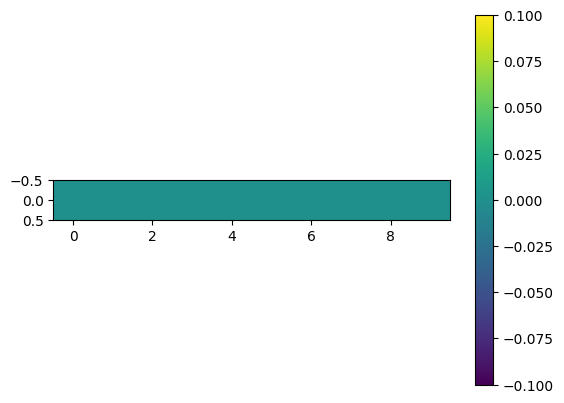

In [18]:
T=9e20
def state(temperature,evecs,evalss):
    state=0
    Z=0
    binary=np.zeros(N)
    for i in range(len(evalss)):
        Z+=np.exp(-evalss[i]/temperature)
    for i in range(len(evalss)):
        weight=(np.exp(-evalss[i]/temperature)/Z)
        a=np.argmax(evecs[:,i]**2)
        spin=np.array([
    1 if x == "1" else -1
    for x in format(a, f"0{N}b")
])
        binary+=weight*spin

    print(binary.shape)
    return binary



plt.imshow(state(T,evector,evalue).reshape(1,N))

plt.colorbar()